# Physics-Informed Neural Network for the Swing Equation

**Contact:** Buxin She ([shebuxin@gmail.com](mailto:shebuxin@gmail.com))  

This notebook introduces a **Physics-Informed Neural Network (PINN)** through a small power-system swing-equation example. The model learns the rotor angle deviation and speed/frequency deviation after a small disturbance.

The goal is to show beginners how a neural network can use both sparse data and physical equations in a fully verifiable setting.

## Table of Contents

0. [Setup](#step-0-setup)
1. [Problem Statement](#step-1-problem-statement)
2. [Governing Physics](#step-2-governing-physics)
3. [Generate Reference Solution](#step-3-generate-reference-solution)
4. [Create Sparse Measurement Data](#step-4-create-sparse-measurement-data)
5. [Ordinary Neural Network Baseline](#step-5-ordinary-neural-network-baseline)
6. [Define the PINN Model](#step-6-define-the-pinn-model)
7. [Define PINN Loss](#step-7-define-pinn-loss)
8. [Train the PINN](#step-8-train-the-pinn)
9. [Evaluate and Compare](#step-9-evaluate-and-compare)
10. [Discussion for Power Systems](#step-10-discussion-for-power-systems)
11. [References](#references)


## Step 0. Setup

We use NumPy for the analytical reference solution, PyTorch for the neural networks and automatic differentiation, and Matplotlib for visualization. The notebook is intentionally small enough to run on a laptop CPU or in Google Colab.


In [1]:
# Step 0. Setup
import random

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

device = torch.device("cpu")
print("Setup complete. PyTorch version:", torch.__version__)
print("Using device:", device)

learning_goal = {
    "input": "time t after a small disturbance",
    "outputs": "rotor angle deviation delta(t) and speed/frequency deviation omega(t)",
    "data": "nine sparse synthetic state samples of delta(t) and omega(t)",
    "physics": "linearized swing equation with synchronizing power coefficient Ks",
    "comparison": "ordinary NN vs PINN",
}

for key, value in learning_goal.items():
    print(f"{key:>10}: {value}")


Setup complete. PyTorch version: 2.12.1
Using device: cpu
     input: time t after a small disturbance
   outputs: rotor angle deviation delta(t) and speed/frequency deviation omega(t)
      data: nine sparse synthetic state samples of delta(t) and omega(t)
   physics: linearized swing equation with synchronizing power coefficient Ks
comparison: ordinary NN vs PINN


## Step 1. Problem Statement

A synchronous generator does not return to a new operating point instantly after a small power imbalance. Its rotor angle can swing around the new equilibrium, and the oscillation gradually decays if damping is present.

We compare two neural-network approaches:

- **ordinary neural network**: trained with the same two-output architecture, the same sparse synthetic rotor-angle and speed/frequency samples, and the same initial condition;
- **PINN**: trained with the same sparse state samples and initial condition, plus the governing swing-equation residuals.

The key idea is that the residual-free ordinary neural network is asked only to fit the sparse state samples and satisfy the initial state. The PINN is asked to fit the same samples and also obey the known electromechanical physics between those points.


In [2]:
problem_summary = {
    "state_1": "delta(t): rotor angle deviation",
    "state_2": "omega(t): speed/frequency deviation, equal to d delta / dt",
    "disturbance": "constant small power imbalance Delta P",
    "expected_shape": "underdamped oscillation with decaying amplitude",
}

for key, value in problem_summary.items():
    print(f"{key:>12}: {value}")

     state_1: delta(t): rotor angle deviation
     state_2: omega(t): speed/frequency deviation, equal to d delta / dt
 disturbance: constant small power imbalance Delta P
expected_shape: underdamped oscillation with decaying amplitude


## Step 2. Governing Physics

For this introductory PINN demo, we directly use the following two-state linearized swing-equation model:

$$
\frac{d\delta}{dt}=\omega,
$$

$$
M\frac{d\omega}{dt} = \Delta P - D\omega - K_s\delta.
$$

Symbol meanings:

- $t$ is time;
- $\delta(t)$ is the small rotor-angle deviation from the pre-disturbance operating point;
- $\omega(t)$ is the speed/frequency deviation and equals $d\delta/dt$;
- $M$ is an equivalent inertia coefficient, with $M>0$;
- $D$ is a damping coefficient, with $D>0$;
- $K_s$ is the synchronizing power coefficient, with $K_s>0$ from the linearized power-angle relationship;
- $\Delta P$ is a constant small net power imbalance after the disturbance. With the sign convention used here, $\Delta P>0$ gives a positive initial acceleration.

This compact state-space form is the physical constraint used later in the PINN residual.


In [3]:
# Step 2. Physical parameters for the linearized swing-equation model.
M = 2.0          # equivalent inertia coefficient
D = 1.0          # damping coefficient; gives zeta = 0.25 with M = Ks = 2
Ks = 2.0         # synchronizing power coefficient from linearized electrical power
delta_p = 0.20   # small normalized power imbalance
T_END = 20.0

omega_n = np.sqrt(Ks / M)
damping_ratio = D / (2.0 * np.sqrt(M * Ks))
omega_d = omega_n * np.sqrt(1.0 - damping_ratio**2)
delta_ss = delta_p / Ks

print(f"M = {M}")
print(f"D = {D}")
print(f"Ks = {Ks}")
print(f"Delta P = {delta_p}")
print(f"Natural frequency omega_n = {omega_n:.4f} rad/s")
print(f"Damping ratio zeta = {damping_ratio:.4f}")
print(f"Damped frequency omega_d = {omega_d:.4f} rad/s")
print(f"Steady-state rotor angle delta_ss = Delta P / Ks = {delta_ss:.4f}")


M = 2.0
D = 1.0
Ks = 2.0
Delta P = 0.2
Natural frequency omega_n = 1.0000 rad/s
Damping ratio zeta = 0.2500
Damped frequency omega_d = 0.9682 rad/s
Steady-state rotor angle delta_ss = Delta P / Ks = 0.1000


## Step 3. Generate Reference Solution

Because this linearized second-order model has a known analytical solution, we can generate a reference curve. This is useful for verification.


Max analytical delta residual: 0.0
Max analytical swing residual: 5.551115123125783e-17


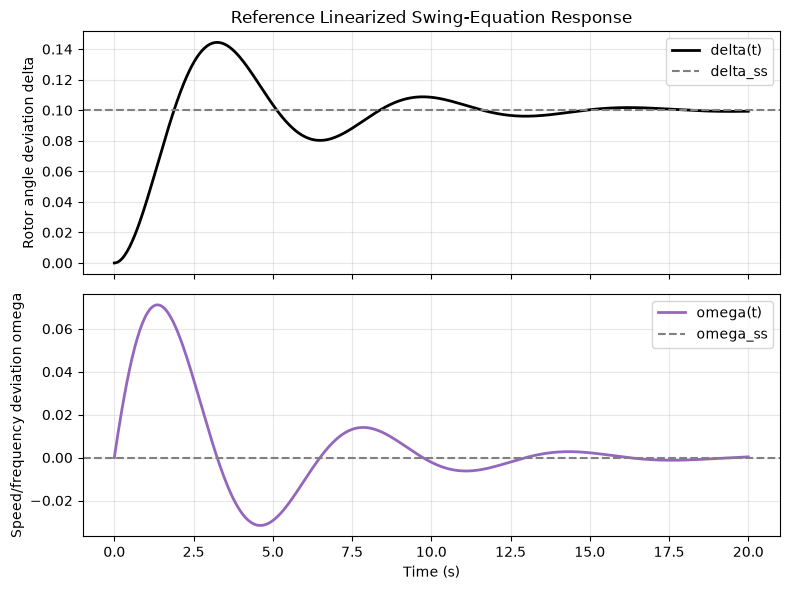

In [4]:
def swing_response_exact(t, M, D, Ks, delta_p):
    """Analytical underdamped step response of M delta_ddot + D delta_dot + Ks delta = delta_p."""
    t_array = np.asarray(t, dtype=float)
    flat_t = t_array.reshape(-1)

    omega_n = np.sqrt(Ks / M)
    zeta = D / (2.0 * np.sqrt(M * Ks))
    if not (0.0 <= zeta < 1.0):
        raise ValueError("This teaching function expects an underdamped case with 0 <= zeta < 1.")

    omega_d = omega_n * np.sqrt(1.0 - zeta**2)
    alpha = zeta * omega_n
    delta_ss = delta_p / Ks

    exp_term = np.exp(-alpha * flat_t)
    sin_term = np.sin(omega_d * flat_t)
    cos_term = np.cos(omega_d * flat_t)

    delta = delta_ss * (1.0 - exp_term * (cos_term + (alpha / omega_d) * sin_term))
    omega = delta_ss * (omega_n**2 / omega_d) * exp_term * sin_term

    return delta.reshape(t_array.shape), omega.reshape(t_array.shape)


t_eval_np = np.linspace(0.0, T_END, 500).reshape(-1, 1)
delta_exact_np, omega_exact_np = swing_response_exact(t_eval_np, M, D, Ks, delta_p)

# Direct residual check for the analytical solution using an independent analytical derivative.
ddelta_exact_dt_np = omega_exact_np
alpha = damping_ratio * omega_n
domega_exact_dt_np = (
    delta_ss
    * (omega_n**2 / omega_d)
    * np.exp(-alpha * t_eval_np)
    * (omega_d * np.cos(omega_d * t_eval_np) - alpha * np.sin(omega_d * t_eval_np))
)
r_delta_exact_np = ddelta_exact_dt_np - omega_exact_np
r_omega_exact_np = M * domega_exact_dt_np + D * omega_exact_np + Ks * delta_exact_np - delta_p
print("Max analytical delta residual:", float(np.max(np.abs(r_delta_exact_np))))
print("Max analytical swing residual:", float(np.max(np.abs(r_omega_exact_np))))

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(t_eval_np, delta_exact_np, color="black", linewidth=2, label="delta(t)")
axes[0].axhline(delta_ss, linestyle="--", color="gray", label="delta_ss")
axes[0].set_ylabel("Rotor angle deviation delta")
axes[0].set_title("Reference Linearized Swing-Equation Response")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(t_eval_np, omega_exact_np, color="tab:purple", linewidth=2, label="omega(t)")
axes[1].axhline(0.0, linestyle="--", color="gray", label="omega_ss")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Speed/frequency deviation omega")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


## Step 4. Create Sparse Measurement Data

To show why physics information helps, we create nine synthetic measurement-like state samples from the analytical solution. These samples are not field measurements; they are noiseless reference values for an introductory, fully verifiable demo.

Both $\delta(t)$ and $\omega(t)$ samples are used as labeled data for the ordinary neural network and for the PINN. This avoids an underconstrained frequency-deviation output in the ordinary baseline. The PINN then receives the same sparse state labels plus the swing-equation residual.


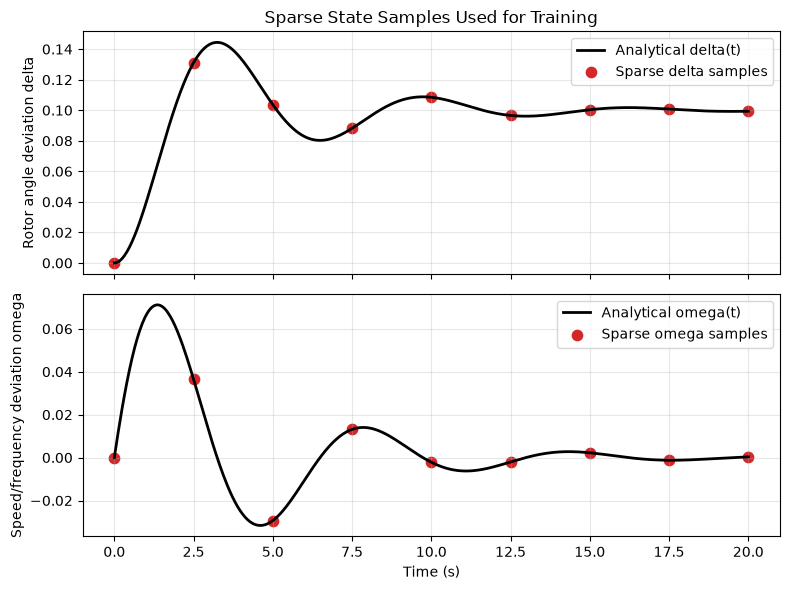

In [5]:
# Step 4. Sparse synthetic state samples
# Nine points keep the data sparse while giving both models enough anchors for a clear teaching demo.
measurement_times = np.linspace(0.0, T_END, 9).reshape(-1, 1)
measurement_delta, measurement_omega = swing_response_exact(measurement_times, M, D, Ks, delta_p)

# Torch tensors used for training
t_data = torch.tensor(measurement_times, dtype=torch.float32, device=device)
delta_data = torch.tensor(measurement_delta, dtype=torch.float32, device=device)
omega_data = torch.tensor(measurement_omega, dtype=torch.float32, device=device)
state_data = torch.cat([delta_data, omega_data], dim=1)
t_eval = torch.tensor(t_eval_np, dtype=torch.float32, device=device)
delta_exact = torch.tensor(delta_exact_np, dtype=torch.float32, device=device)
omega_exact = torch.tensor(omega_exact_np, dtype=torch.float32, device=device)

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(t_eval_np, delta_exact_np, color="black", linewidth=2, label="Analytical delta(t)")
axes[0].scatter(measurement_times, measurement_delta, color="tab:red", s=55, label="Sparse delta samples")
axes[0].set_ylabel("Rotor angle deviation delta")
axes[0].set_title("Sparse State Samples Used for Training")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(t_eval_np, omega_exact_np, color="black", linewidth=2, label="Analytical omega(t)")
axes[1].scatter(measurement_times, measurement_omega, color="tab:red", s=55, label="Sparse omega samples")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Speed/frequency deviation omega")
axes[1].grid(True, alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()


## Step 5. Ordinary Neural Network Baseline

First, we train a small ordinary neural network with the same two-output architecture used by the PINN:

$$
[\hat{\delta}(t), \hat{\omega}(t)].
$$

For data fairness, this ordinary neural network uses the same sparse synthetic rotor-angle and speed/frequency samples as the PINN, together with the initial condition $\delta(0)=0,\omega(0)=0$. In plain words, omega samples are used as training labels for the ordinary baseline. Without an $\omega$ term in the loss, the ordinary network's frequency-deviation output would be almost unconstrained except at the initial point.

After training, we also plot the **Ordinary NN training loss**. This makes the tutorial explicit that the ordinary baseline is a trained model, not a curve drawn directly from the analytical solution.

In this simple fixed-disturbance demo, the neural-network input is the time variable $t$, not the rotor angle. The outputs are the state estimates $\hat{\delta}(t)$ and $\hat{\omega}(t)$. This follows the usual PINN viewpoint. The network approximates the solution of a differential equation as a function of its independent variable. More realistic power-system PINN or surrogate-model versions usually use time together with input variables, such as disturbance level, control signal, or model parameters.


Ordinary NN delta MAE against analytical solution: 0.012836
Ordinary NN omega MAE against analytical solution: 0.015541


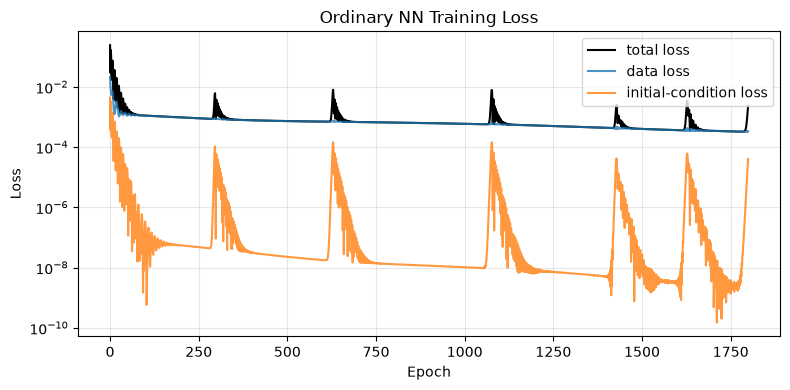

In [6]:
class MLP(nn.Module):
    """Small fully connected network mapping time t to one or more state variables."""

    def __init__(self, output_dim=2, hidden=64, t_end=T_END):
        super().__init__()
        self.t_end = float(t_end)
        self.net = nn.Sequential(
            nn.Linear(1, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, output_dim),
        )

    def forward(self, t):
        tau = 2.0 * t / self.t_end - 1.0
        return self.net(tau)


def train_data_only_model(model, t_data, state_data, epochs=1800, lr=1e-3):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    mse = nn.MSELoss()
    history = {"total_loss": [], "data_loss": [], "ic_loss": []}

    for epoch in range(epochs):
        pred_data = model(t_data)
        data_loss = mse(pred_data, state_data)

        pred_initial = model(t_initial)
        ic_loss = mse(pred_initial, initial_state)
        total_loss = data_loss + lambda_ic_data_only * ic_loss

        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()

        history["total_loss"].append(float(total_loss.item()))
        history["data_loss"].append(float(data_loss.item()))
        history["ic_loss"].append(float(ic_loss.item()))
    return history


lambda_ic_data_only = 50.0
t_initial = torch.zeros((1, 1), dtype=torch.float32, device=device)
initial_state = torch.zeros((1, 2), dtype=torch.float32, device=device)

data_model = MLP(output_dim=2).to(device)
data_only_history = train_data_only_model(data_model, t_data, state_data)

with torch.no_grad():
    data_only_pred = data_model(t_eval)
    data_only_delta_pred = data_only_pred[:, 0:1]
    data_only_omega_pred = data_only_pred[:, 1:2]
    data_only_delta_mae = torch.mean(torch.abs(data_only_delta_pred - delta_exact)).item()
    data_only_omega_mae = torch.mean(torch.abs(data_only_omega_pred - omega_exact)).item()

print(f"Ordinary NN delta MAE against analytical solution: {data_only_delta_mae:.6f}")
print(f"Ordinary NN omega MAE against analytical solution: {data_only_omega_mae:.6f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(data_only_history["total_loss"], label="total loss", color="black")
ax.semilogy(data_only_history["data_loss"], label="data loss", alpha=0.8)
ax.semilogy(data_only_history["ic_loss"], label="initial-condition loss", alpha=0.8)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Ordinary NN Training Loss")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## Step 6. Define the PINN Model

The PINN uses the same NN architecture as the ordinary baseline. The key difference is the loss function, which adds swing-equation residuals computed with automatic differentiation.


In [7]:
pinn_model = MLP(output_dim=2).to(device)
print(pinn_model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=2, bias=True)
  )
)


## Step 7. Define PINN Loss

For neural-network predictions $\hat{\delta}(t)$ and $\hat{\omega}(t)$, the two physics residuals are

$$
r_{\delta}(t)=\frac{d\hat{\delta}}{dt}-\hat{\omega},
$$

$$
r_{\omega}(t)=M\frac{d\hat{\omega}}{dt}+D\hat{\omega}+K_s\hat{\delta}-\Delta P.
$$

The PINN minimizes three terms:

$$
\mathcal{L}_{data}=\text{MSE}([\hat{\delta}(t_{data}),\hat{\omega}(t_{data})],[\delta_{data},\omega_{data}]),
$$

$$
\mathcal{L}_{physics}=\text{MSE}(r_{\delta},0)+\text{MSE}(r_{\omega},0),
$$

$$
\mathcal{L}_{IC}=\text{MSE}(\hat{\delta}(0),0)+\text{MSE}(\hat{\omega}(0),0).
$$

The total loss is

$$
\mathcal{L}=\mathcal{L}_{data}+\lambda_{physics}\mathcal{L}_{physics}+\lambda_{IC}\mathcal{L}_{IC}.
$$


In [8]:
def physics_residual(model, t_collocation, M, D, Ks, delta_p):
    """Compute swing-equation residuals using PyTorch autograd."""
    t_for_grad = t_collocation.clone().detach().requires_grad_(True)
    prediction = model(t_for_grad)
    delta_hat = prediction[:, 0:1]
    omega_hat = prediction[:, 1:2]

    d_delta_dt = torch.autograd.grad(
        delta_hat,
        t_for_grad,
        grad_outputs=torch.ones_like(delta_hat),
        create_graph=True,
    )[0]
    d_omega_dt = torch.autograd.grad(
        omega_hat,
        t_for_grad,
        grad_outputs=torch.ones_like(omega_hat),
        create_graph=True,
    )[0]

    r_delta = d_delta_dt - omega_hat
    r_omega = M * d_omega_dt + D * omega_hat + Ks * delta_hat - delta_p
    return r_delta, r_omega


lambda_physics = 50.0
lambda_ic = 50.0
mse = nn.MSELoss()

t_collocation = torch.linspace(0.0, T_END, 300, device=device).reshape(-1, 1)
t_initial = torch.zeros((1, 1), dtype=torch.float32, device=device)
initial_state = torch.zeros((1, 2), dtype=torch.float32, device=device)

# Check residual shapes before training.
initial_r_delta, initial_r_omega = physics_residual(pinn_model, t_collocation, M, D, Ks, delta_p)
print("r_delta tensor shape:", tuple(initial_r_delta.shape))
print("r_omega tensor shape:", tuple(initial_r_omega.shape))


r_delta tensor shape: (300, 1)
r_omega tensor shape: (300, 1)


## Step 8. Train the PINN

The PINN sees the same sparse state samples and the same initial condition as the ordinary neural network, plus collocation points where the swing-equation residuals are evaluated. These collocation points do not require measured labels.

We first use Adam for a stable initial fit and then use a short L-BFGS refinement step, a common choice in PINN examples, to reduce the physical residual.


Adam epoch  500 | total=6.651e-02 | data=4.982e-04 | physics=8.957e-04 | ic=4.246e-04


Adam epoch 1000 | total=3.374e-02 | data=3.570e-04 | physics=5.226e-04 | ic=1.451e-04


Adam epoch 1500 | total=2.288e-02 | data=2.833e-04 | physics=3.899e-04 | ic=6.202e-05


Adam epoch 2000 | total=1.300e-02 | data=2.008e-04 | physics=2.267e-04 | ic=2.925e-05


Adam epoch 2500 | total=5.813e-03 | data=1.076e-04 | physics=1.070e-04 | ic=7.113e-06


After L-BFGS | total=3.208e-04 | data=1.397e-05 | physics=6.107e-06 | ic=2.968e-08
PINN training finished.


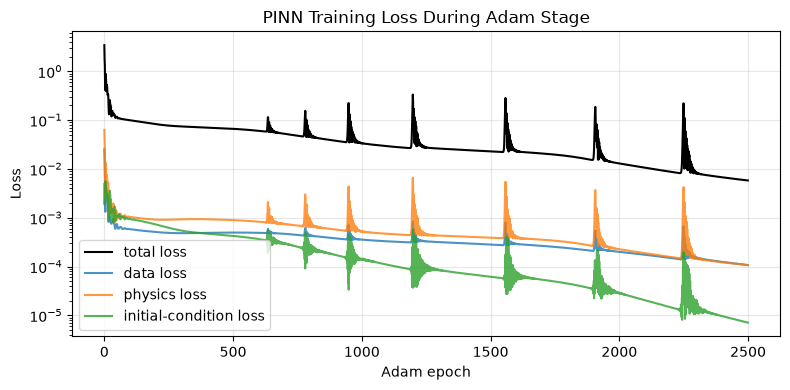

In [9]:
def compute_pinn_losses(model):
    pred_data = model(t_data)
    data_loss = mse(pred_data, state_data)

    r_delta, r_omega = physics_residual(model, t_collocation, M, D, Ks, delta_p)
    physics_loss = mse(r_delta, torch.zeros_like(r_delta)) + mse(r_omega, torch.zeros_like(r_omega))

    pred_initial = model(t_initial)
    ic_loss = mse(pred_initial, initial_state)

    total_loss = data_loss + lambda_physics * physics_loss + lambda_ic * ic_loss
    return total_loss, data_loss, physics_loss, ic_loss


def train_pinn_model(model, adam_epochs=2500, adam_lr=1e-3, lbfgs_steps=350):
    adam = optim.Adam(model.parameters(), lr=adam_lr)
    history = {"total_loss": [], "data_loss": [], "physics_loss": [], "ic_loss": []}

    for epoch in range(1, adam_epochs + 1):
        total_loss, data_loss, physics_loss, ic_loss = compute_pinn_losses(model)

        adam.zero_grad()
        total_loss.backward()
        adam.step()

        history["total_loss"].append(float(total_loss.item()))
        history["data_loss"].append(float(data_loss.item()))
        history["physics_loss"].append(float(physics_loss.item()))
        history["ic_loss"].append(float(ic_loss.item()))

        if epoch % 500 == 0:
            print(
                f"Adam epoch {epoch:4d} | total={total_loss.item():.3e} | "
                f"data={data_loss.item():.3e} | physics={physics_loss.item():.3e} | ic={ic_loss.item():.3e}"
            )

    # A short L-BFGS refinement often improves PINN residuals after Adam has found a good basin.
    lbfgs = optim.LBFGS(
        model.parameters(),
        lr=0.8,
        max_iter=lbfgs_steps,
        max_eval=lbfgs_steps,
        tolerance_grad=1e-9,
        tolerance_change=1e-11,
        line_search_fn="strong_wolfe",
    )

    def closure():
        total_loss, _, _, _ = compute_pinn_losses(model)
        lbfgs.zero_grad()
        total_loss.backward()
        return total_loss

    lbfgs.step(closure)
    total_loss, data_loss, physics_loss, ic_loss = compute_pinn_losses(model)
    print(
        f"After L-BFGS | total={total_loss.item():.3e} | "
        f"data={data_loss.item():.3e} | physics={physics_loss.item():.3e} | ic={ic_loss.item():.3e}"
    )
    return history


pinn_history = train_pinn_model(pinn_model)
print("PINN training finished.")

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(pinn_history["total_loss"], label="total loss", color="black")
ax.semilogy(pinn_history["data_loss"], label="data loss", alpha=0.8)
ax.semilogy(pinn_history["physics_loss"], label="physics loss", alpha=0.8)
ax.semilogy(pinn_history["ic_loss"], label="initial-condition loss", alpha=0.8)
ax.set_xlabel("Adam epoch")
ax.set_ylabel("Loss")
ax.set_title("PINN Training Loss During Adam Stage")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## Step 9. Evaluate and Compare

We compare the ordinary neural network and the PINN against the analytical swing-equation solution.

The Ordinary NN curves are obtained by evaluating the trained ordinary neural network on the full time grid `t_eval` after it has been trained on the sparse state samples.


Ordinary NN delta MAE:  0.012836
Ordinary NN omega MAE:  0.015541
PINN delta MAE:         0.003345
PINN omega MAE:         0.003075
Ordinary NN delta RMSE: 0.020015
Ordinary NN omega RMSE: 0.024981
PINN delta RMSE:        0.004070
PINN omega RMSE:        0.003767
PINN residual MAE on collocation points: 1.315814e-03
Accuracy checks passed against the analytical swing-equation solution.


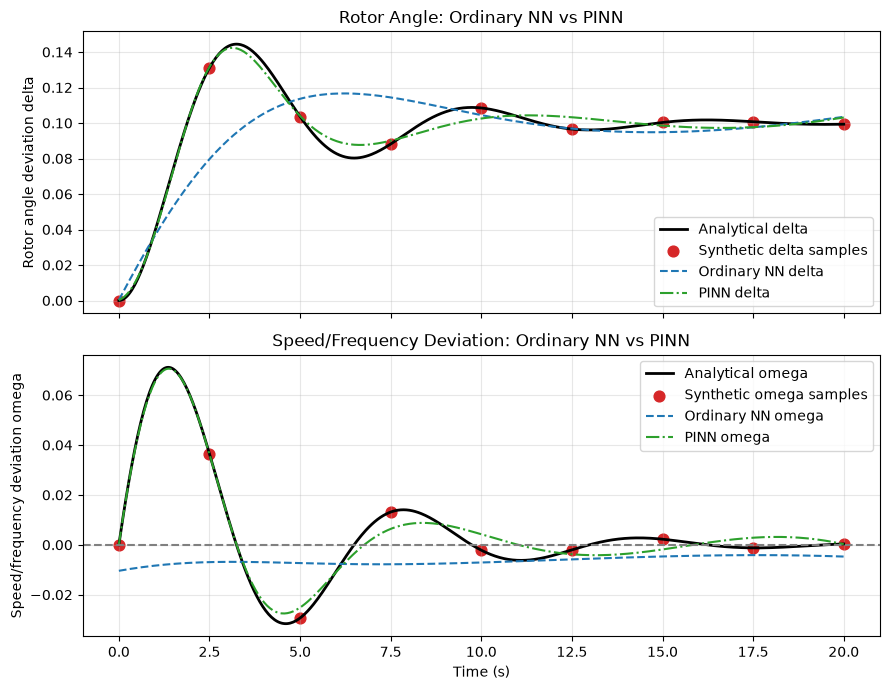

In [10]:
with torch.no_grad():
    # Evaluate the trained data_model and trained pinn_model on the full time grid.
    data_only_pred = data_model(t_eval)
    data_only_delta_pred = data_only_pred[:, 0:1]
    data_only_omega_pred = data_only_pred[:, 1:2]

    pinn_pred = pinn_model(t_eval)
    pinn_delta_pred = pinn_pred[:, 0:1]
    pinn_omega_pred = pinn_pred[:, 1:2]

    data_only_delta_mae = torch.mean(torch.abs(data_only_delta_pred - delta_exact)).item()
    data_only_omega_mae = torch.mean(torch.abs(data_only_omega_pred - omega_exact)).item()
    pinn_delta_mae = torch.mean(torch.abs(pinn_delta_pred - delta_exact)).item()
    pinn_omega_mae = torch.mean(torch.abs(pinn_omega_pred - omega_exact)).item()
    data_only_delta_rmse = torch.sqrt(torch.mean((data_only_delta_pred - delta_exact) ** 2)).item()
    data_only_omega_rmse = torch.sqrt(torch.mean((data_only_omega_pred - omega_exact) ** 2)).item()
    pinn_delta_rmse = torch.sqrt(torch.mean((pinn_delta_pred - delta_exact) ** 2)).item()
    pinn_omega_rmse = torch.sqrt(torch.mean((pinn_omega_pred - omega_exact) ** 2)).item()

pinn_eval_r_delta, pinn_eval_r_omega = physics_residual(pinn_model, t_collocation, M, D, Ks, delta_p)
pinn_residual_mae = 0.5 * (
    torch.mean(torch.abs(pinn_eval_r_delta)).item() + torch.mean(torch.abs(pinn_eval_r_omega)).item()
)

print(f"Ordinary NN delta MAE:  {data_only_delta_mae:.6f}")
print(f"Ordinary NN omega MAE:  {data_only_omega_mae:.6f}")
print(f"PINN delta MAE:         {pinn_delta_mae:.6f}")
print(f"PINN omega MAE:         {pinn_omega_mae:.6f}")
print(f"Ordinary NN delta RMSE: {data_only_delta_rmse:.6f}")
print(f"Ordinary NN omega RMSE: {data_only_omega_rmse:.6f}")
print(f"PINN delta RMSE:        {pinn_delta_rmse:.6f}")
print(f"PINN omega RMSE:        {pinn_omega_rmse:.6f}")
print(f"PINN residual MAE on collocation points: {pinn_residual_mae:.6e}")

PINN_DELTA_MAE_TOLERANCE = 0.006
PINN_OMEGA_MAE_TOLERANCE = 0.006
PINN_RESIDUAL_MAE_TOLERANCE = 0.003
assert pinn_delta_mae < PINN_DELTA_MAE_TOLERANCE, "PINN delta MAE is too far from the analytical solution."
assert pinn_omega_mae < PINN_OMEGA_MAE_TOLERANCE, "PINN omega MAE is too far from the analytical solution."
assert pinn_residual_mae < PINN_RESIDUAL_MAE_TOLERANCE, "PINN residual is too large on the collocation grid."
assert pinn_delta_mae <= data_only_delta_mae, "PINN should be at least as accurate as the data-only baseline for delta."
assert pinn_omega_mae <= data_only_omega_mae, "PINN should be at least as accurate as the data-only baseline for omega."
print("Accuracy checks passed against the analytical swing-equation solution.")

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
axes[0].plot(t_eval_np, delta_exact_np, color="black", linewidth=2, label="Analytical delta")
axes[0].scatter(measurement_times, measurement_delta, color="tab:red", s=60, label="Synthetic delta samples")
axes[0].plot(t_eval_np, data_only_delta_pred.cpu().numpy(), linestyle="--", color="tab:blue", label="Ordinary NN delta")
axes[0].plot(t_eval_np, pinn_delta_pred.cpu().numpy(), linestyle="-.", color="tab:green", label="PINN delta")
axes[0].set_ylabel("Rotor angle deviation delta")
axes[0].set_title("Rotor Angle: Ordinary NN vs PINN")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(t_eval_np, omega_exact_np, color="black", linewidth=2, label="Analytical omega")
axes[1].scatter(measurement_times, measurement_omega, color="tab:red", s=60, label="Synthetic omega samples")
axes[1].plot(t_eval_np, data_only_omega_pred.cpu().numpy(), linestyle="--", color="tab:blue", label="Ordinary NN omega")
axes[1].plot(t_eval_np, pinn_omega_pred.cpu().numpy(), linestyle="-.", color="tab:green", label="PINN omega")
axes[1].axhline(0.0, linestyle="--", color="gray")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Speed/frequency deviation omega")
axes[1].set_title("Speed/Frequency Deviation: Ordinary NN vs PINN")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


In [11]:
print("Key takeaway:")
print("A PINN can learn rotor-angle and speed trajectories while respecting swing-equation residuals.")

Key takeaway:
A PINN can learn rotor-angle and speed trajectories while respecting swing-equation residuals.


## Step 10. Discussion for Power Systems
The ordinary neural network is a residual-free baseline. It is trained with the same sparse synthetic $\delta(t)$ and $\omega(t)$ state samples and the same initial condition as the PINN. The PINN uses the same data and architecture, but adds the swing-equation residual to make the predicted trajectory obey the known electromechanical physics between the sparse samples.

In this fixed-disturbance demo, the network input is only time $t$. More realistic power-system PINN or surrogate-model studies usually include both $t$ and input variables, such as disturbance size, control inputs, operating condition, or uncertain model parameters.


## References

The physical model and terminology in this notebook are based on standard power-system stability references rather than invented equations:

1. P. Kundur, *Power System Stability and Control*. New York, NY, USA: McGraw-Hill, 1994.
2. P. Kundur et al., "Definition and Classification of Power System Stability IEEE/CIGRE Joint Task Force on Stability Terms and Definitions," *IEEE Transactions on Power Systems*, vol. 19, no. 3, pp. 1387-1401, Aug. 2004, doi: [10.1109/TPWRS.2004.825981](https://doi.org/10.1109/TPWRS.2004.825981).
3. M. Bakhtvar, E. Vittal, K. Zheng, and A. Keane, "Synchronizing Torque Impacts on Rotor Speed in Power Systems," *IEEE Transactions on Power Systems*, vol. 32, no. 3, pp. 1927-1935, May 2017, doi: [10.1109/TPWRS.2016.2600478](https://doi.org/10.1109/TPWRS.2016.2600478).
4. M. Raissi, P. Perdikaris, and G. E. Karniadakis, "Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations," *Journal of Computational Physics*, vol. 378, pp. 686-707, Feb. 2019, doi: [10.1016/j.jcp.2018.10.045](https://doi.org/10.1016/j.jcp.2018.10.045).
5. G. S. Misyris, A. Venzke, and S. Chatzivasileiadis, "Physics-Informed Neural Networks for Power Systems," arXiv: [1911.03737](https://arxiv.org/abs/1911.03737), 2019.
